# 8. 생성형 AI를 활용한 제조 결함 데이터 생성 실습

**박서준** | 한양대학교 ERICA 인공지능학과

강의에서 받은 실습 노트북 두 개(8-1 Stable Diffusion 실습, 8-2 AnomalyAny 실습)를 하나로 이어서 Colab에서 실행하고, 결과와 회고를 정리했습니다.

- Part 1 (8-1): Stable Diffusion으로 텍스트로 이미지 생성, 인페인팅(마스크 부분만 다시 그리기), PCB 정상 이미지에 결함 넣어 보기(추가 실험)
- Part 2 (8-2): AnomalyAny(EPFL, CVPR 2025)로 정상 이미지와 결함 문장을 넣어 table, hazelnut, pcb 결함 이미지 생성
- 실행 환경: Colab A100 GPU, diffusers 0.33.1, transformers 4.52.4 (강의 환경 버전에 맞춤)
- 실행일: 2026-10-12

**전체 실행 흐름**

```text
(Part 1) SD 1.5 텍스트→이미지 → SD 1.5 인페인팅(회색 이미지, 해변 사진) → PCB 정상 이미지 인페인팅(추가)
        ↓  GPU 메모리 정리
(Part 2) AnomalyAny 설치 → 정상 이미지 + 결함 문장 → 결함 이미지와 attention map 생성 (table → hazelnut → pcb)
```

- 원본 코드에서 바꾼 부분은 셀 안에 주석으로 이유를 적었습니다. (버전 맞춰 설치, 내려간 inpainting 모델 교체, Colab에서 안 되는 autoreload 주석 처리 등)
- 결과 확인용으로 추가한 셀은 첫 줄에 `# 추가한 셀`이라고 적었습니다.
- 중간중간 **확인한 점**을 적었고, 회고는 맨 아래에 있습니다.

# Part 1. Stable Diffusion 기본 실습 (8-1)

In [1]:
# Colab 기본 버전으로는 실습 코드(특히 Part 2의 AnomalyAny)가 맞지 않을 수 있어서,
# 아래 셀에 주석으로 적혀 있는 강의 환경 버전(diffusers 0.33.1, transformers 4.52.4)으로 맞춰 설치했습니다.
!pip install -q diffusers==0.33.1 transformers==4.52.4 accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 114.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 149.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 113.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import diffusers
import transformers

diffusers.__version__

'0.33.1'

In [3]:
transformers.__version__

'4.52.4'

In [4]:
# !pip install diffusers==0.33.1
# !pip install transformers==4.52.4

In [5]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [6]:
from diffusers import StableDiffusionPipeline, StableDiffusionInpaintPipeline
from PIL import Image
import matplotlib.pyplot as plt

def display_image(image):
    plt.imshow(image)
    plt.axis('off')
    plt.show()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

...

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Text-to-Image pipeline loaded.
Generating image for prompt: 'A photo of man riding a horse in the moon wearing astronaut outfits'


  0%|          | 0/30 [00:00<?, ?it/s]

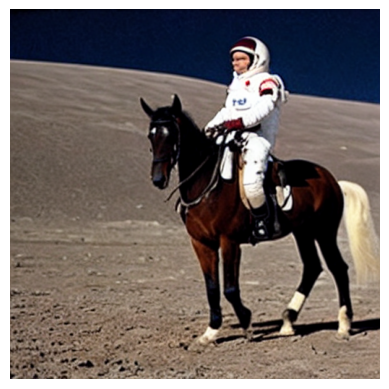

Image saved as generated_defect_0.png


In [7]:
# --- 1.1 파이프라인 로드 ---
model_id_text2img = "runwayml/stable-diffusion-v1-5"
pipe_text2img = StableDiffusionPipeline.from_pretrained(model_id_text2img, torch_dtype=torch.float16)
pipe_text2img = pipe_text2img.to(device)
print("Text-to-Image pipeline loaded.")

# --- 1.2 프롬프트 정의 및 이미지 생성 ---
prompt_defect = "A photo of man riding a horse in the moon wearing astronaut outfits"
negative_prompt = "blurry, deformed, cartoon, painting, illustration, normal, no defect"

# 파라미터 설정
num_steps = 30
guidance_scale_val = 8.5
num_images_per_prompt = 1 # 한 번에 여러 개 생성 가능

print(f"Generating image for prompt: '{prompt_defect}'")
# seed 고정으로 재현성 확보 (선택 사항)
generator = torch.Generator(device=device).manual_seed(42)

with torch.autocast("cuda"): # float16 연산 시
    generated_images = pipe_text2img(
        prompt_defect,
        negative_prompt=negative_prompt,
        num_inference_steps=num_steps,
        guidance_scale=guidance_scale_val,
        num_images_per_prompt=num_images_per_prompt,
        # generator=generator
    ).images

# --- 1.3 결과 확인 및 저장 ---
for i, image in enumerate(generated_images):
    display_image(image)
    try:
        image.save(f"generated_defect_{i}.png")
        print(f"Image saved as generated_defect_{i}.png")
    except Exception as e:
        print(f"Error saving image: {e}")


**확인한 점**
- 강의 코드 그대로 "말을 타고 달 위에 있는 우주복 입은 사람"을 생성했습니다. A100에서 30 step이 3초 정도로 빨랐습니다.
- 변수 이름은 `prompt_defect`인데 실제 프롬프트는 결함과 상관없는 예시 문장이라, 텍스트만으로 이미지를 만드는 기본 동작을 확인하는 단계라고 이해했습니다.
- `generator`를 만들어 두고 실제 호출에서는 주석 처리돼 있어서, 실행할 때마다 다른 이미지가 나옵니다.

model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

vocab.json: 0.00B [00:00, ?B/s]

unet/diffusion_pytorch_model.fp16.safete(…):   0%|          | 0.00/1.72G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.fp16.safeten(…):   0%|          | 0.00/167M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Inpainting pipeline loaded.
Using placeholder initial image and mask.


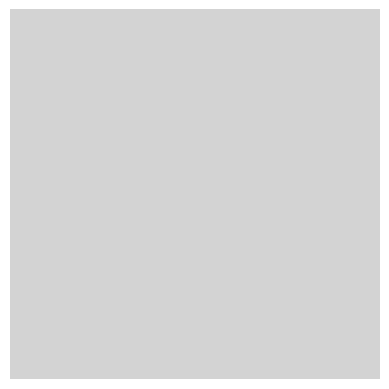

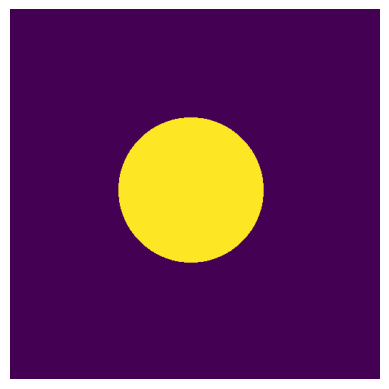

Inpainting with prompt: 'A deep circular dent with rough edges'


  0%|          | 0/50 [00:00<?, ?it/s]

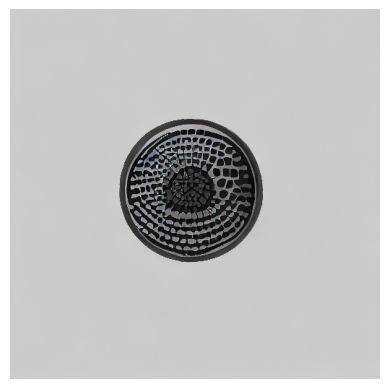

Image saved as inpainted_defect_0.png


In [8]:
# --- 2.1 파이프라인 로드 ---
# Inpainting 전용 모델 사용
# 원래 모델(stabilityai/stable-diffusion-2-inpainting)이 Hugging Face에서 404로 내려가 있어서, 같은 역할의 SD 1.5 inpainting 모델로 바꿨습니다.
# model_id_inpaint = "stabilityai/stable-diffusion-2-inpainting"
model_id_inpaint = "stable-diffusion-v1-5/stable-diffusion-inpainting" # 또는 다른 inpainting 모델
try:
    # SD 1.5 inpainting 저장소에는 float32 safetensors 파일이 없어서, fp16 버전(variant="fp16")으로 받도록 했습니다.
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(model_id_inpaint, torch_dtype=torch.float16, variant="fp16")
    pipe_inpaint = pipe_inpaint.to(device)
    print("Inpainting pipeline loaded.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}. Skipping inpainting part or use a general pipeline.")
    pipe_inpaint = None # 예외 처리

if pipe_inpaint:
    # --- 2.2 원본 이미지 및 마스크 준비 ---
    init_image = Image.new("RGB", (512, 512), "lightgray") # 밝은 회색 배경
    mask_image = Image.new("L", (512, 512), "black")
    from PIL import ImageDraw
    draw = ImageDraw.Draw(mask_image)
    draw.ellipse(((150, 150), (350, 350)), fill="white") # 중앙 흰색 원형 마스크
    print("Using placeholder initial image and mask.")
    display_image(init_image)
    display_image(mask_image)


    # --- 2.3 프롬프트 정의 및 이미지 생성 ---
    prompt_inpaint_defect = "A deep circular dent with rough edges"
    negative_prompt_inpaint = "smooth, perfect, flat, no dent, blurry"

    print(f"Inpainting with prompt: '{prompt_inpaint_defect}'")
    with torch.autocast("cuda"):
        inpainted_images = pipe_inpaint(
            prompt=prompt_inpaint_defect,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt_inpaint,
            num_inference_steps=50, # Inpainting은 조금 더 많은 step이 필요할 수 있음
            guidance_scale=7.5
        ).images

    # --- 2.4 결과 확인 및 저장 ---
    for i, image in enumerate(inpainted_images):
        display_image(image)
        try:
            image.save(f"inpainted_defect_{i}.png")
            print(f"Image saved as inpainted_defect_{i}.png")
        except Exception as e:
            print(f"Error saving image: {e}")

# TODO: 다양한 원본 이미지, 마스크, 프롬프트로 실험해보세요!
#       예: 실제 정상 제품 이미지에 사용자가 직접 그린 마스크 적용

**확인한 점**
- 원래 모델 `stabilityai/stable-diffusion-2-inpainting`은 Hugging Face에서 내려가 있어서(404) SD 1.5 inpainting 모델로 바꿨습니다. 바꾼 뒤에도 `diffusion_pytorch_model.bin`을 못 찾는다는 오류가 났는데, 이 저장소에는 float32 safetensors 파일이 없고 fp16 파일만 있어서 `variant="fp16"`을 추가해 해결했습니다.
- 회색 배경의 원형 마스크 부분에만 "깊게 파인 원형 찍힘(dent)"을 그리게 했는데, 결과는 찍힘이라기보다 격자무늬가 있는 동그란 물체처럼 보였습니다.
- 마스크를 `plt.imshow`로 그릴 때 컬러맵을 지정하지 않아서 흰색과 검은색이 노란색과 보라색으로 보입니다. 표시만 그렇게 보이는 것이고 실제 마스크에는 문제가 없습니다.

Using device: cuda


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Inpainting pipeline loaded with stable-diffusion-v1-5/stable-diffusion-inpainting.
Image loaded and resized to 512x512.


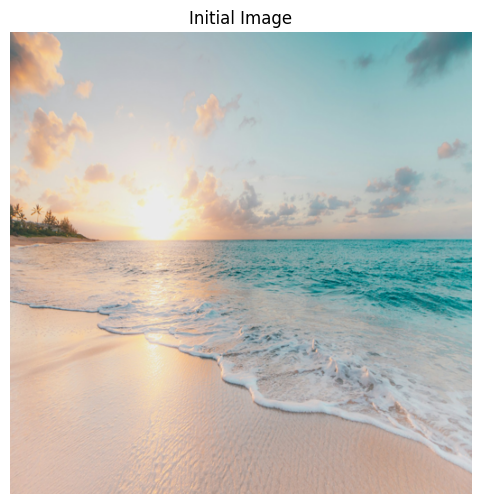

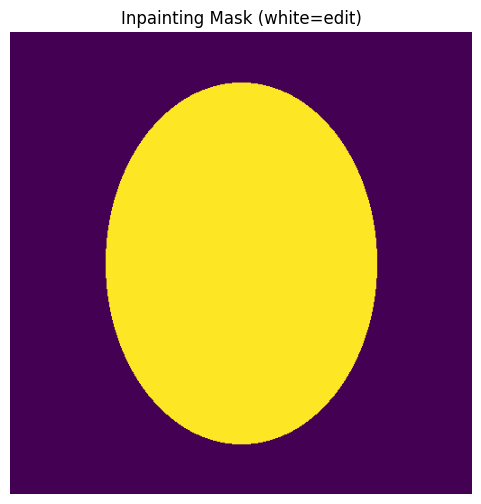

Running inpainting with prompt: A treasure chest buried in the sand


  0%|          | 0/50 [00:00<?, ?it/s]

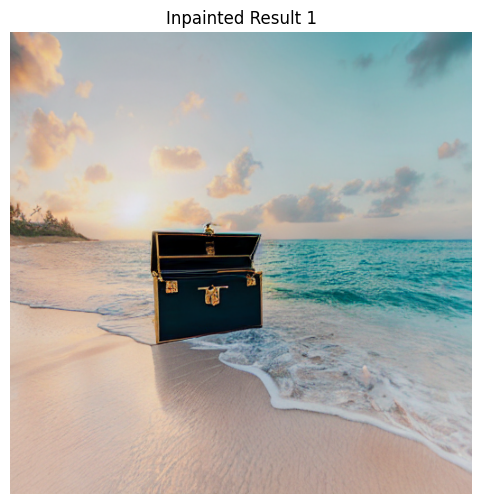

Saved: result_inpainted_0.png


In [9]:
import torch
from diffusers import StableDiffusionInpaintPipeline
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import requests
from io import BytesIO

# --- 1. 디바이스 설정 ---
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# --- 2. 이미지 시각화 함수 ---
def display_image(image, title="Generated Image"):
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(title)
    plt.axis('off')
    plt.show()

# --- 3. 파이프라인 로딩 ---
# 위 셀과 같은 이유로 inpainting 모델을 SD 1.5 inpainting으로 바꿨습니다.
# model_id_inpaint = "stabilityai/stable-diffusion-2-inpainting"
model_id_inpaint = "stable-diffusion-v1-5/stable-diffusion-inpainting"
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
        model_id_inpaint,
        torch_dtype=torch.float16 if device == "cuda" else torch.float32,
        variant="fp16"  # 위 셀과 같은 이유로 fp16 파일을 받도록 추가
    )
    pipe_inpaint = pipe_inpaint.to(device)
    print(f"Inpainting pipeline loaded with {model_id_inpaint}.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}")
    pipe_inpaint = None

# --- 4. 이미지와 마스크 준비 ---
if pipe_inpaint:
    # 이미지 로드
    image_url = "https://images.unsplash.com/photo-1507525428034-b723cf961d3e?q=80&w=2070&auto=format&fit=crop"
    try:
        response = requests.get(image_url)
        response.raise_for_status()
        init_image = Image.open(BytesIO(response.content)).convert("RGB").resize((512, 512))
        print("Image loaded and resized to 512x512.")
    except Exception as e:
        print(f"Image load failed: {e}. Using placeholder image.")
        init_image = Image.new("RGB", (512, 512))
        draw = ImageDraw.Draw(init_image)
        draw.rectangle([0, 0, 512, 280], fill="skyblue")
        draw.rectangle([0, 280, 512, 512], fill="goldenrod")
        draw.ellipse([400, 60, 440, 100], fill="gold")

    # 마스크 생성 (중앙 타원형)
    mask_image = Image.new("L", (512, 512), 0)  # 검정 배경
    draw = ImageDraw.Draw(mask_image)
    ellipse_box = [106, 56, 406, 456]  # 대략 중앙 타원 (너비 300, 높이 400)
    draw.ellipse(ellipse_box, fill=255)  # 흰색 영역을 인페인팅할 영역으로

    # 이미지 확인
    display_image(init_image, "Initial Image")
    display_image(mask_image, "Inpainting Mask (white=edit)")

    # --- 5. 프롬프트 정의 ---
    prompt = "A treasure chest buried in the sand"
    negative_prompt = "blurry, deformed, cartoon, illustration, watermark, text, signature, extra limbs"

    print(f"Running inpainting with prompt: {prompt}")

    generator = torch.Generator(device=device).manual_seed(1234)

    # --- 6. 인페인팅 수행 ---
    if device == "cuda":
        with torch.autocast("cuda"):
            result = pipe_inpaint(
                prompt=prompt,
                image=init_image,
                mask_image=mask_image,
                negative_prompt=negative_prompt,
                guidance_scale=8.5,
                num_inference_steps=50,
                generator=generator
            )
    else:
        result = pipe_inpaint(
            prompt=prompt,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt,
            guidance_scale=8.5,
            num_inference_steps=50,
            generator=generator
        )

    # --- 7. 결과 출력 및 저장 ---
    if result and result.images:
        for i, out_img in enumerate(result.images):
            display_image(out_img, f"Inpainted Result {i+1}")
            out_img.save(f"result_inpainted_{i}.png")
            print(f"Saved: result_inpainted_{i}.png")
    else:
        print("No images returned from inpainting.")

else:
    print("Pipeline not loaded. Cannot run inpainting.")


**확인한 점**
- 해변 사진 가운데 타원 영역만 다시 그려서 "모래에 묻힌 보물상자"를 넣었습니다. 하늘, 바다, 모래와 자연스럽게 이어져서 인페인팅이 주변 맥락을 잘 따라간다는 걸 확인했습니다.
- 다만 보물상자가 모래에 묻혀 있다기보다는 모래 위에 놓인 모습이라, 프롬프트의 "buried"까지 정확히 반영되지는 않았습니다.
- 이 셀은 seed를 1234로 고정해서, 프롬프트나 마스크를 바꿔 가며 비교하기 좋습니다.

  0%|          | 0/50 [00:00<?, ?it/s]

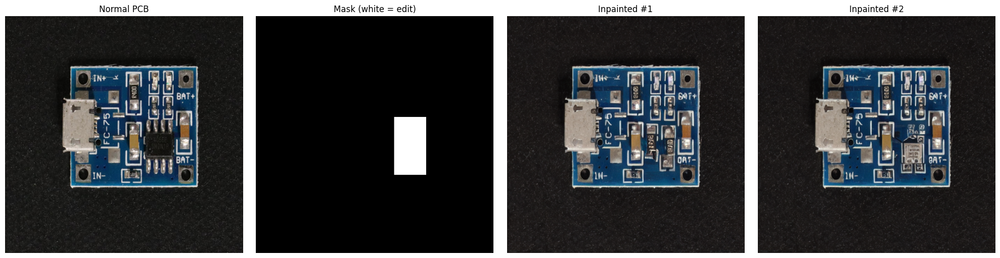

In [10]:
# 추가한 셀: 위 코드 TODO에 있던 "실제 정상 제품 이미지에 마스크 적용"을 직접 해봤습니다.
# 강의 자료의 PCB 정상 이미지(normal.png)에서 가운데 칩 부분만 마스크로 칠하고, 그 부분에만 탄 자국(burnt)을 그리게 했습니다.
!gdown -q 1sxnp0fmdDJOfuRyQ07e0zQeetA4RytrS -O normal.png

pcb_image = Image.open('normal.png').convert('RGB').resize((512, 512))
pcb_mask = Image.new('L', (512, 512), 0)
ImageDraw.Draw(pcb_mask).rectangle([298, 218, 366, 342], fill=255)  # 가운데 8핀 칩 위치

pcb_prompt = 'a close-up photo of a burnt black scorch mark on an electronic chip, damaged circuit board'
pcb_negative = 'clean, normal, undamaged, blurry, cartoon, text'

generator = torch.Generator(device=device).manual_seed(0)
with torch.autocast('cuda'):
    pcb_results = pipe_inpaint(
        prompt=pcb_prompt,
        image=pcb_image,
        mask_image=pcb_mask,
        negative_prompt=pcb_negative,
        num_inference_steps=50,
        guidance_scale=7.5,
        num_images_per_prompt=2,
        generator=generator
    ).images

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(pcb_image)
axes[0].set_title('Normal PCB')
axes[1].imshow(pcb_mask, cmap='gray')
axes[1].set_title('Mask (white = edit)')
for i, img in enumerate(pcb_results):
    axes[i + 2].imshow(img)
    axes[i + 2].set_title(f'Inpainted #{i + 1}')
    img.save(f'pcb_burnt_{i}.png')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**확인한 점 (추가 실험)**
- 칩 위치만 마스크로 지정하고 "탄 자국(burnt scorch mark)"을 넣으라고 했는데, 두 장 모두 탄 자국 대신 **칩이 다른 부품으로 바뀐 이미지**가 나왔습니다. 1번은 작은 저항 같은 부품 2개, 2번은 은색의 다른 부품이 칩 자리에 생겼습니다.
- 의도한 burnt는 아니지만, 6번 실습의 VisA pcb4에 있던 `missing`, `wrong place` 같은 결함처럼 보이는 이미지가 만들어졌습니다. Stable Diffusion이 결함보다는 주변 PCB와 어울리는 "그럴듯한 부품"을 먼저 그리는 것 같습니다.
- 마스크 밖의 `IN+`, `BAT+` 글자도 조금 뭉개졌습니다. 인페인팅 결과도 VAE로 이미지 전체를 다시 복원해서 그런 것 같습니다. 학습 데이터로 쓰려면 마스크 밖은 원본 픽셀로 다시 덮는 후처리가 필요해 보입니다.

In [11]:
# 추가한 셀: Part 2에서 Stable Diffusion을 float32로 새로 불러오기 전에, Part 1 파이프라인을 지워 GPU 메모리를 비웠습니다.
import gc
for name in ['pipe_text2img', 'pipe_inpaint']:
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()
print(f'현재 GPU 메모리 사용량: {torch.cuda.memory_allocated() / 1024**3:.2f} GB')

현재 GPU 메모리 사용량: 0.01 GB


# Part 2. 최신 연구(AnomalyAny)를 활용한 결함 데이터 생성 (8-2)

In [12]:
# AnomalyAny 코드가 쓰는 라이브러리(OpenAI CLIP, pyrallis, ftfy)가 Colab에 없어서 같이 설치했습니다.
!pip install -q ftfy pyrallis git+https://github.com/openai/CLIP.git
!git clone https://github.com/EPFL-IMOS/AnomalyAny

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.9 MB/s eta 0:00:00
Cloning into 'AnomalyAny'...
remote: Enumerating objects: 87, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 87 (delta 26), reused 19 (delta 19), pack-reused 53 (from 1)
Receiving objects: 100% (87/87), 17.84 MiB | 21.98 MiB/s, done.
Resolving deltas: 100% (29/29), done.


In [13]:
import os
os.chdir('AnomalyAny')
print("현재 디렉토리:", os.getcwd())

현재 디렉토리: /content/AnomalyAny


**Reference:** 이 코드는 EPFL-IMOS의 [AnomalyAny GitHub 리포지토리](https://github.com/EPFL-IMOS/AnomalyAny)에서 가져왔습니다.

In [14]:
from typing import List, Dict
import torch

import sys
sys.path.append(".")
sys.path.append("..")

from clip_pipeline_attend_and_excite import RelationalAttendAndExcitePipeline
from config import RunConfig
from run import run_on_prompt, get_indices_to_alter, run_on_prompt_and_image, run_on_prompt_and_masked_image
from utils import vis_utils
from utils.ptp_utils import AttentionStore, show_cross_attention_binary

from utils.vis_utils import vis_ann

from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"

# Colab(Python 3.13)에서는 autoreload 확장이 삭제된 imp 모듈을 불러오다 오류가 나서 주석 처리했습니다.
# 저장소 코드를 고치면서 실행하는 게 아니라서 빼도 결과에는 영향이 없습니다.
# %load_ext autoreload
# %autoreload 2

In [15]:
NUM_DIFFUSION_STEPS = 200
GUIDANCE_SCALE = 12.5
MAX_NUM_WORDS = 77
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
stable = RelationalAttendAndExcitePipeline.from_pretrained("runwayml/stable-diffusion-v1-5", safety_checker=None).to(device)
tokenizer = stable.tokenizer

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'clip_pipeline_attend_and_excite.RelationalAttendAndExcitePipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


**AnomalyAny가 하는 일 (코드와 README를 보고 정리)**
- 정상 이미지(`image_guidance`)를 가이드로 넣고, "a photo of a hazelnut with a crack on it"처럼 결함이 들어간 문장으로 Stable Diffusion을 돌립니다. 정상 이미지의 모습을 유지하면서 결함만 추가하는 것이 목표입니다.
- `tokens = "8"`은 문장에서 8번째 단어(`faded`, `crack`)를 뜻합니다. 생성 초반에 이 단어의 cross-attention이 약하면 latent를 직접 고쳐서 결함이 꼭 나타나게 합니다(Attend-and-Excite 방식).
- 여기에 CLIP(ViT-L/14)으로 생성 이미지와 더 자세한 결함 설명(`detailed_prompt`)의 유사도를 계산해서 결함 모양을 다듬습니다. 그래서 일반 생성보다 훨씬 느리고 GPU 메모리도 많이 씁니다.
- 결과로 생성 이미지와 결함 단어의 attention map이 같이 나와서, 모델이 결함을 어디에 그렸는지 볼 수 있습니다.

**실행하면서 막힌 부분**
- `%load_ext autoreload`가 Colab(Python 3.13)에서 `imp` 모듈이 없다는 오류를 내서 주석 처리했습니다.
- 처음에는 L4 GPU(22GB)로 돌렸는데 table 생성 첫 단계에서 CUDA out of memory가 났습니다. AnomalyAny README에 "GPU 메모리 30GB 미만에서 돌아가도록 최적화했다"고 적혀 있는 걸 보면 22GB인 L4로는 부족했던 것 같습니다. A100으로 바꾸고 노트북 전체를 다시 실행했습니다.

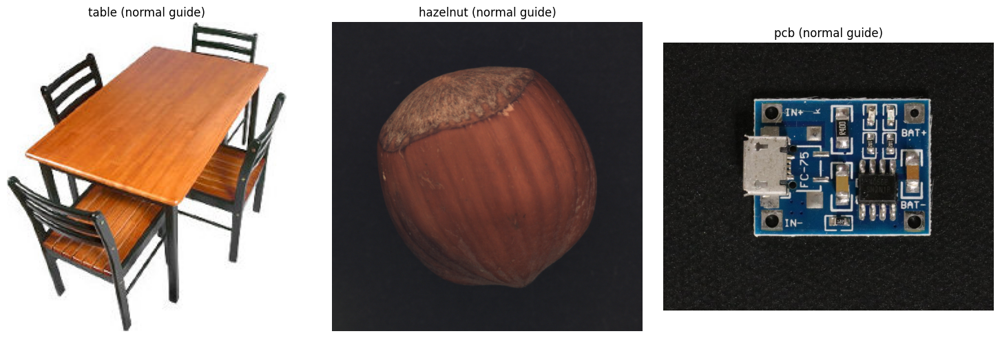

In [28]:
# 추가한 셀: 원본 코드의 image_guidance.show()가 Colab에서는 이미지를 띄우지 못해서, 가이드로 넣은 정상 이미지 3장을 따로 확인했습니다.
guide_paths = {'table': './example_web/table.jpg', 'hazelnut': './example_image/000.png', 'pcb': 'normal.png'}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, p) in zip(axes, guide_paths.items()):
    ax.imshow(Image.open(p).convert('RGB'))
    ax.set_title(f'{name} (normal guide)')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [16]:
from PIL import Image

type = "table"
tokens = "8"
prompt = f"a photo of a {type} that is faded"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with areas of discoloration or lightening due to prolonged sun exposure"

root_path = f"./example_web/"
image_guidance_path = root_path + "table.jpg"


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

In [17]:
def run_and_display(prompts: List[str],
                    controller: AttentionStore,
                    indices_to_alter: List[int],
                    init_image: Image.Image,
                    init_image_guidance_scale: float,
                    mask_image: str,
                    generator: torch.Generator,
                    run_standard_sd: bool = False,
                    scale_factor: int = 20,
                    thresholds: Dict[int, float] = {0: 0.05, 10: 0.5, 20: 0.8},
                    max_iter_to_alter: int = 25,
                    display_output: bool = False,
                    normal_prompt=normal_prompt,
                    detailed_prompt=detailed_prompt):
    config = RunConfig(prompt=prompts[0],
                       run_standard_sd=run_standard_sd,
                       scale_factor=scale_factor,
                       thresholds=thresholds,
                       max_iter_to_alter=max_iter_to_alter,
                       n_inference_steps=NUM_DIFFUSION_STEPS,
                       guidance_scale=GUIDANCE_SCALE)
    image, image_latent = run_on_prompt_and_masked_image(model=stable,
                          prompt=prompts,
                          controller=controller,
                          token_indices=indices_to_alter,
                          init_image=init_image,
                          init_image_guidance_scale=init_image_guidance_scale,
                          mask_image=mask_image,
                          seed=generator,
                          config=config,
                          normal_prompt=normal_prompt,
                          detailed_prompt=detailed_prompt)
    if display_output:
        display(image)
    return image, image_latent

# Anomaly Generation

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'table',
 6: 'that',
 7: 'is',
 8: 'faded'}
Altering tokens: ['faded']


100%|████████████████████████████████████████| 890M/890M [00:04<00:00, 225MiB/s]
100%|████████████████████████████████████████| 244M/244M [00:01<00:00, 194MiB/s]
/content/AnomalyAny/clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels


  0%|          | 0/200 [00:00<?, ?it/s]

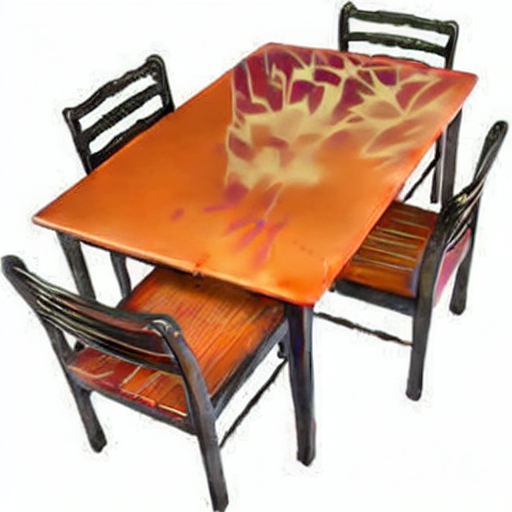

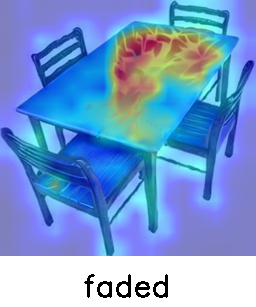

In [18]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

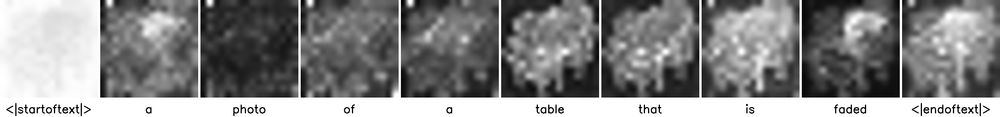

In [19]:
images, attention_maps = show_cross_attention_binary(controller, tokenizer, prompts, res=16, from_where=("up", "mid", "down"))

In [20]:
# 추가한 셀: 원본 코드가 생성 시간을 compute_time에 모으기만 하고 출력하지 않아서 직접 출력했습니다.
print('seed:', seeds)
print(f'table 1장 생성 시간: {compute_time[0]:.1f}초')

seed: [64125]
table 1장 생성 시간: 203.2초


**확인한 점**
- 테이블 윗면에 "faded(색이 바랜)" 결함이 생겼습니다. attention map에서도 `faded` 단어가 테이블 윗면에 집중돼 있어서, 결함이 어디에 그려졌는지 확인할 수 있었습니다.
- 다만 색이 바랬다기보다는 주황색과 노란색 얼룩이 크게 번진 모습이라, 실제로 햇빛에 바랜 느낌과는 조금 달랐습니다.
- 1장 생성에 203.2초(A100)가 걸렸습니다. step 수도 다르지만 앞의 일반 Stable Diffusion(30 step에 약 3초)과 비교하면 훨씬 오래 걸려서, 결함 데이터를 많이 만들려면 시간 비용을 따져 봐야 할 것 같습니다.

In [21]:
from PIL import Image

type = "hazelnut"
tokens = "8"
prompt = f"a photo of a {type} with a crack on it"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with a large, jagged crack exposing the interior."

image_num = str('000')
root_path = f"./example_image/"
image_guidance_path = root_path + image_num + '.png'


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'hazelnut',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


  0%|          | 0/200 [00:00<?, ?it/s]

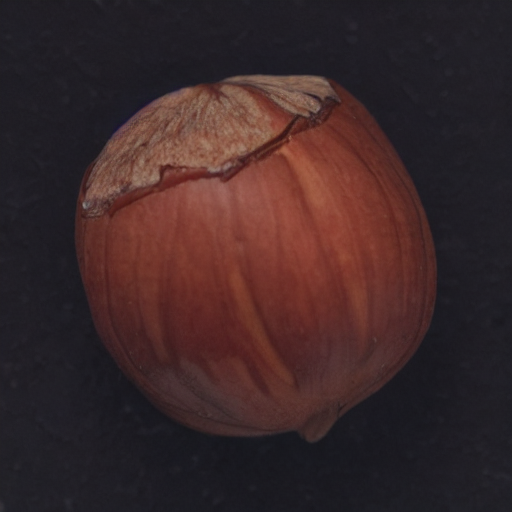

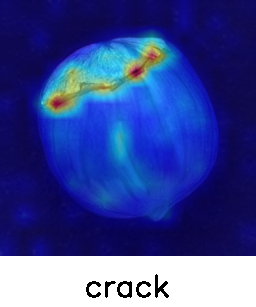

  0%|          | 0/200 [00:00<?, ?it/s]

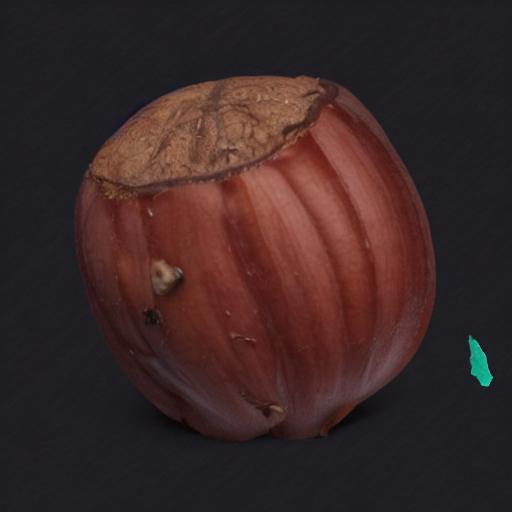

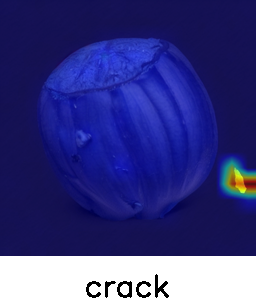

  0%|          | 0/200 [00:00<?, ?it/s]

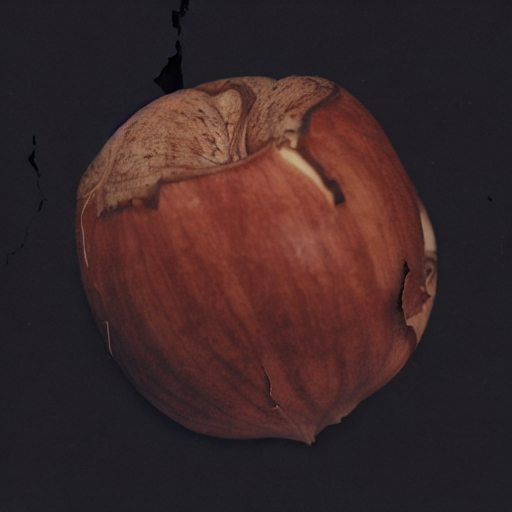

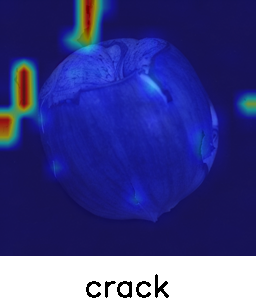

  0%|          | 0/200 [00:00<?, ?it/s]

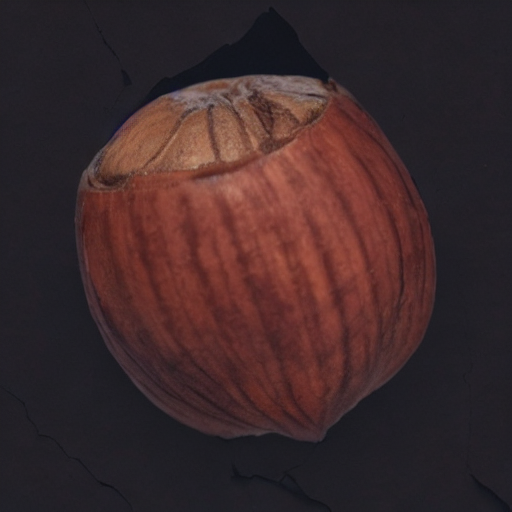

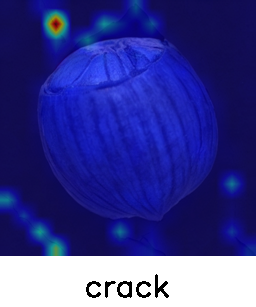

In [23]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000), random.randint(0, 100000),random.randint(0, 100000),random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

In [24]:
# 추가한 셀: hazelnut 4장의 seed와 생성 시간
print('seeds:', seeds)
print('생성 시간(초):', [round(t, 1) for t in compute_time], f'/ 평균 {sum(compute_time) / len(compute_time):.1f}초')

seeds: [19843, 43680, 40516, 68047]
생성 시간(초): [197.4, 196.1, 196.1, 197.7] / 평균 196.8초


**확인한 점** (seed 4개, 평균 196.8초)
- 1번(seed 19843)은 껍질 윗부분이 갈라진 모양이 생겼고, `crack` attention도 갈라진 선을 따라 빨갛게 나타나서 결함 위치가 잘 맞았습니다.
- 나머지 3장은 결함이 헤이즐넛보다 **배경(바닥)**에 생긴 경우가 많았습니다. 2번은 배경에 하늘색 얼룩이 생기고 attention도 그쪽에 몰렸고, 3번과 4번은 바닥에 금이 간 모양이 생겼습니다.
- 코드에서 `mask_image=None`으로 두어 결함 위치를 제한하지 않았기 때문인 것 같습니다. README에도 `mask_image`가 "결함 위치를 정하는 선택 옵션"이라고 되어 있고, 저장소에 `example_image/fg_mask/000.png`(헤이즐넛 전경 마스크)가 있어서 다음에 넣어 보고 싶습니다.
- 4장의 생성 시간은 196.1초부터 197.7초까지로 거의 같았습니다.

In [25]:
# 강의 자료 폴더에 있는 PCB 정상 이미지(normal.png)를 받아왔습니다. (원본 코드는 이 파일이 이미 있다고 가정)
!gdown -q 1sxnp0fmdDJOfuRyQ07e0zQeetA4RytrS -O normal.png

from PIL import Image

type = "pcb"
tokens = "8"
prompt = f"a photo of a {type} with a crack on it"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with a large, jagged crack exposing the interior."

image_guidance_path = 'normal.png'


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


/content/AnomalyAny/clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels


  0%|          | 0/200 [00:00<?, ?it/s]

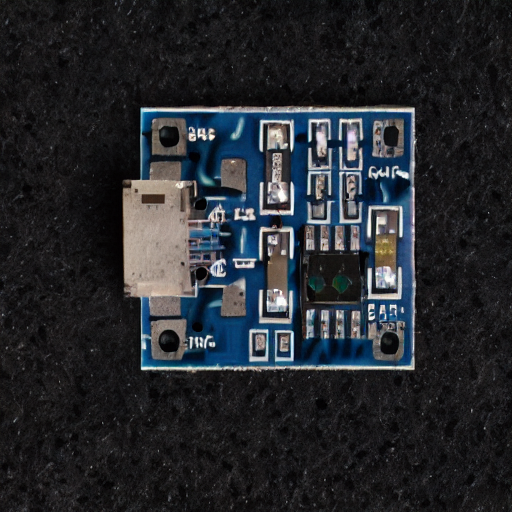

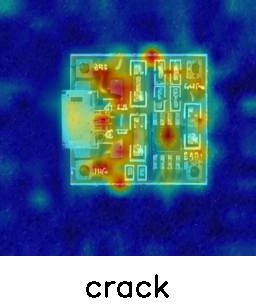

  0%|          | 0/200 [00:00<?, ?it/s]

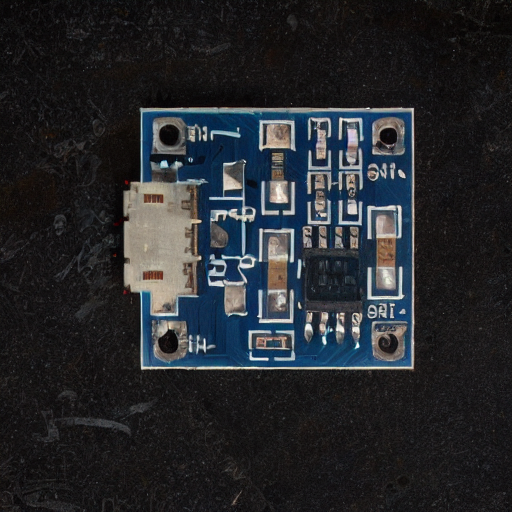

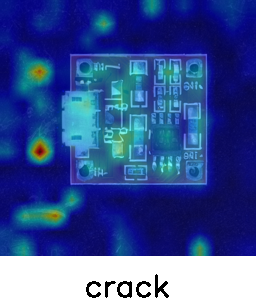

  0%|          | 0/200 [00:00<?, ?it/s]

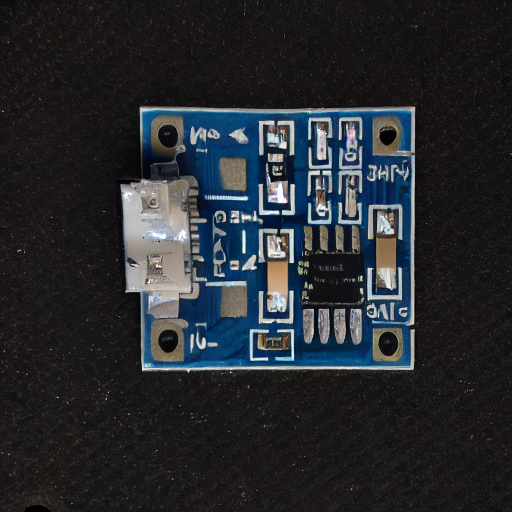

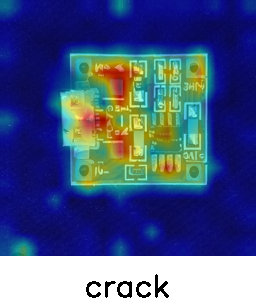

  0%|          | 0/200 [00:00<?, ?it/s]

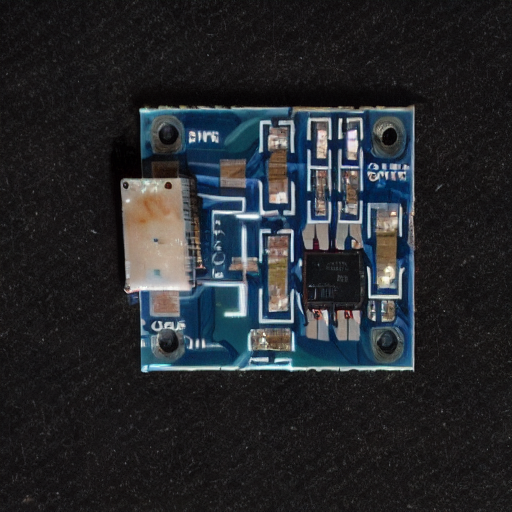

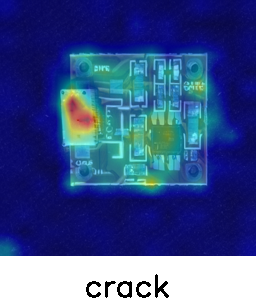

In [26]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000), random.randint(0, 100000),random.randint(0, 100000),random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

In [27]:
# 추가한 셀: pcb 4장의 seed와 생성 시간
print('seeds:', seeds)
print('생성 시간(초):', [round(t, 1) for t in compute_time], f'/ 평균 {sum(compute_time) / len(compute_time):.1f}초')

seeds: [69553, 21240, 91014, 64401]
생성 시간(초): [196.5, 196.6, 194.9, 195.1] / 평균 195.8초


**확인한 점** (seed 4개, 평균 195.8초)
- 강의 자료의 PCB 정상 이미지에 "crack"을 넣었는데, 4장 모두 뚜렷한 금(crack)보다는 **USB 커넥터 변색, 부품 모양 변형, 보드 글자 뭉개짐** 같은 변화가 생겼습니다. 4번(seed 64401)은 USB 커넥터가 녹슨 것처럼 변색됐고 attention도 커넥터 쪽에 모였습니다.
- 2번(seed 21240)은 attention이 보드 바깥 배경에 몰려 있어서, hazelnut처럼 결함이 물체 밖으로 새는 경우가 있었습니다.
- 4장 모두 보드의 `IN+`, `BAT+` 같은 글자가 깨졌습니다. 정상 이미지를 가이드로 넣어도 Stable Diffusion이 글자를 정확히 다시 그리지 못해서, 결함이 아닌 부분까지 바뀐 것 같습니다.
- hazelnut은 모양이 단순해서 결과가 비교적 자연스러웠지만, PCB처럼 작은 부품과 글자가 많은 이미지는 "결함만 추가"하기가 더 어려워 보였습니다.

## 회고

### 1. 실습 내용

정상 제품 이미지는 많고 불량 이미지는 부족한 제조 현장의 문제를 생성형 AI로 풀어 보는 실습이었습니다. Part 1에서는 Stable Diffusion으로 이미지 생성과 인페인팅을 해 봤고, Part 2에서는 AnomalyAny로 정상 이미지에 결함을 추가한 이미지를 만들었습니다.

| 실험 | 입력 | 결과 | 생성 시간 (A100) |
|---|---|---|---:|
| SD 1.5 텍스트→이미지 | 문장 | 달 위의 우주비행사 | 3초 이내 (30 step) |
| SD 1.5 인페인팅 | 회색 이미지 + 원형 마스크 | 격자무늬 동그란 물체 | 3초 이내 (50 step) |
| SD 1.5 인페인팅 (추가 실험) | PCB 정상 이미지 + 칩 마스크 | 칩이 다른 부품으로 바뀜 | 3초 이내 (50 step, 2장) |
| AnomalyAny | table + faded | 윗면에 얼룩 | 203.2초 (200 step) |
| AnomalyAny | hazelnut + crack (4장) | 1장은 껍질 갈라짐, 3장은 배경에 결함 | 평균 196.8초 |
| AnomalyAny | PCB + crack (4장) | 커넥터 변색과 부품 변형, 글자 깨짐 | 평균 195.8초 |

### 2. 어려웠던 점과 해결 과정

강의 코드를 그대로 실행하면 안 되는 부분이 생각보다 많았습니다. Colab 환경 설정과 오류 원인 정리에는 AI 도구의 도움을 받았습니다.

1. **모델이 사라짐**: SD 2 inpainting 모델이 Hugging Face에서 내려가 404가 났습니다. SD 1.5 inpainting으로 바꿨지만 float32 파일이 없어서 다시 오류가 났고, `variant="fp16"`으로 해결했습니다.
2. **환경 차이**: Colab이 Python 3.13이라 `%load_ext autoreload`가 `imp` 모듈 오류를 냈습니다. 실행 결과에는 필요 없는 부분이라 주석 처리했습니다.
3. **GPU 메모리 부족**: L4(22GB)에서 AnomalyAny를 돌리자 CUDA out of memory가 났습니다. 생성 중간에 CLIP ViT-L/14까지 쓰는 구조라 메모리를 많이 쓰는 것 같아서, A100으로 바꿔 전체를 다시 실행했습니다.

오류가 나면 코드가 틀렸다고 먼저 생각했는데, 이번에는 대부분 **모델 저장소, 파이썬 버전, GPU 같은 환경 문제**였습니다. 같은 코드라도 언제, 어디서 돌리느냐에 따라 결과가 달라질 수 있다는 걸 느꼈습니다.

### 3. 결과를 보면서 생각한 점

- 일반 Stable Diffusion에 결함을 문장으로만 요청하면, 결함보다 "그럴듯한 정상 부품"을 그리는 경향이 있었습니다. PCB 칩 자리에 탄 자국 대신 다른 부품이 생긴 것이 그 예입니다.
- AnomalyAny는 결함 단어에 attention을 강제로 모아서 table과 hazelnut 1번처럼 결함이 확실히 보이는 결과를 만들었습니다. 하지만 위치를 지정하지 않으면 결함이 배경에 생기기도 해서, 학습 데이터로 쓰려면 사람이 한 번 걸러야 할 것 같습니다.
- 생성한 결함 이미지에는 정답 마스크가 없습니다. 6번 실습처럼 이상탐지 모델을 평가하는 데 쓰려면 attention map을 마스크처럼 쓸 수 있는지도 확인이 필요하다고 생각했습니다.
- 한 장에 약 3분이 걸려서, 불량 이미지 수백 장을 만들려면 시간과 GPU 비용이 꽤 들 것 같습니다.

### 4. KPT 회고

#### Keep: 계속 유지하고 싶은 점
- 오류가 날 때마다 원인과 바꾼 내용을 셀 주석에 바로 적어 둔 점을 유지하고 싶습니다. 나중에 다시 실행할 때 무엇을 왜 바꿨는지 바로 알 수 있었습니다.
- 생성 이미지만 보지 않고 attention map을 같이 확인한 점이 좋았습니다. 결함이 물체가 아니라 배경에 생긴 경우를 attention map으로 찾을 수 있었습니다.

#### Problem: 아쉬웠던 점
- 생성 결과가 좋은지 나쁜지를 눈으로만 판단했고, 숫자로 평가하지 못했습니다.
- seed가 랜덤이라 같은 조건으로 다시 만들기 어렵고, 장수도 4장씩이라 경향을 말하기에는 적었습니다.
- PCB 인페인팅에서 마스크 밖까지 바뀌는 문제를 확인만 하고 고치지는 못했습니다.

#### Try: 다음에 해볼 일
- hazelnut 실험에 저장소의 `fg_mask/000.png`를 `mask_image`로 넣어서, 결함이 헤이즐넛 안에만 생기는지 seed를 고정하고 4장씩 비교해 보겠습니다.
- PCB 인페인팅 결과에서 마스크 밖은 원본 픽셀로 다시 덮어서, 글자가 뭉개지지 않는 결함 이미지를 만들어 보겠습니다.
- 만든 PCB 결함 이미지를 6번 실습의 PaDiM 모델에 넣어서 이상 점수가 정상보다 높게 나오는지 확인하겠습니다. 생성한 이미지가 실제 불량처럼 보이는지 확인하는 간단한 평가가 될 것 같습니다.

이번 실습으로 생성형 AI가 불량 데이터 부족 문제를 **줄여 줄 수는 있지만, 그대로 믿고 쓸 수는 없다**는 걸 느꼈습니다. 다음에는 "만들기"보다 "만든 데이터가 쓸 만한지 확인하는 방법"에 더 시간을 써 보고 싶습니다.